In [84]:
import os
import pickle as pkl

import numpy as np

from pydeseq2.datasets import load_example_data
from pydeseq2.dds import DeseqDataSet
from pydeseq2.default_inference import DefaultInference
from pydeseq2.ds import DeseqStats

counts_df = load_example_data(
    modality="raw_counts",
    dataset="synthetic", 
    debug=False,
)

metadata = load_example_data(
    modality="metadata",
    dataset="synthetic",
    debug=False,
)

inference = DefaultInference(n_cpus=8)
dds = DeseqDataSet(
    counts=counts_df,
    metadata=metadata,
    design="~condition",  # compare samples based on the "condition"
    # column ("B" vs "A")
    refit_cooks=True,
    inference=inference,
)

dds.fit_size_factors()

dds.obs["size_factors"]

sample1      1.228981
sample2      1.188774
sample3      0.997222
sample4      1.002158
sample5      0.834577
               ...   
sample96     1.269359
sample97     0.743998
sample98     0.739878
sample99     0.958880
sample100    0.635708
Name: size_factors, Length: 100, dtype: float64

In [85]:
import os
import pickle as pkl

import pandas as pd

from pydeseq2.dds import DeseqDataSet
from pydeseq2.default_inference import DefaultInference
from pydeseq2.ds import DeseqStats

# Replace this with the path to directory where you would like results to be saved
OUTPUT_PATH = "../output_files/synthetic_example/"
os.makedirs(OUTPUT_PATH, exist_ok=True)  # Create path if it doesn't exist

# Analysis 1
DATA_PATH = "https://raw.githubusercontent.com/owkin/PyDESeq2/main/datasets/synthetic/"

In [86]:
from pydeseq2.datasets import load_example_data

import pandas as pd


# Preview the columns to verify structur

counts_df = load_example_data(
    modality="raw_counts", dataset="synthetic", debug=False
).T  # genes × samples

meta_data = load_example_data(
    modality="metadata", dataset="synthetic", debug=False
)  # indexed by sample IDs



In [87]:

gene_annotations_df = pd.DataFrame(index=counts_df.index)
gene_annotations_df.index.name = "Geneid"

In [88]:
gene_annotations = gene_annotations_df.copy()

In [89]:
count_matrix_transposed = counts_df.T
sample_info = meta_data.loc[count_matrix_transposed.index].copy()
gene_annotations_df = pd.DataFrame(index=counts_df.index) 

In [90]:
counts_df = counts_df.T
print(counts_df)

Geneid     gene1  gene2  gene3  gene4  gene5  gene6  gene7  gene8  gene9  \
sample1       12     21      4    130     18      0     16     54     49   
sample2        1     44      2     63     11     10     70     32     57   
sample3        4      4     11    180     21      3     28     34     65   
sample4        1     10      2    100     44      9     28     16     33   
sample5        1     11      6    135     16      2     32     29     31   
...          ...    ...    ...    ...    ...    ...    ...    ...    ...   
sample96       7     26      3     67     11      4     41     44     54   
sample97       1     14      3     71     33      5     19     42     25   
sample98      10     36      2     72     11      2     66     27     16   
sample99      18     14      3     66     53     11     32     19     79   
sample100     21      9      3     42     13     13     19     78     30   

Geneid     gene10  
sample1         3  
sample2         9  
sample3         2  
sample4

In [91]:
samples_to_keep = ~metadata.condition.isna()
counts_df = counts_df.loc[samples_to_keep]
metadata = metadata.loc[samples_to_keep]

In [92]:
genes_to_keep = counts_df.columns[counts_df.sum(axis=0) >= 10]
counts_df = counts_df[genes_to_keep]

In [93]:
inference = DefaultInference(n_cpus=8)
dds = DeseqDataSet(
    counts=counts_df,
    metadata=metadata,
    design="~condition",
    refit_cooks=True,
    inference=inference,
) #create a DeSeqDataSet object with the counts and metadata, specfying the design formula

In [94]:
dds.deseq2()

In [95]:
print(dds)

AnnData object with n_obs × n_vars = 100 × 10
    obs: 'condition', 'group', 'size_factors', 'replaceable'
    var: '_normed_means', 'non_zero', '_MoM_dispersions', 'genewise_dispersions', '_genewise_converged', 'fitted_dispersions', 'MAP_dispersions', '_MAP_converged', 'dispersions', '_outlier_genes', '_LFC_converged', 'replaced', 'refitted', '_pvalue_cooks_outlier'
    uns: 'trend_coeffs', 'disp_function_type', '_squared_logres', 'prior_disp_var'
    obsm: 'design_matrix', '_mu_LFC', '_hat_diagonals'
    varm: 'LFC'
    layers: None (.X), 'normed_counts', '_mu_hat', 'cooks'


In [96]:
with open(os.path.join(OUTPUT_PATH, "result_adata.pkl"), "wb") as f:
    pkl.dump(dds.to_picklable_anndata(), f)

In [97]:
print(dds.var["dispersions"])

Geneid
gene1     0.882598
gene2     0.222578
gene3     0.837238
gene4     0.158970
gene5     0.249926
gene6     0.973647
gene7     0.235155
gene8     0.198781
gene9     0.186520
gene10    0.631900
Name: dispersions, dtype: float64


In [98]:
ds = DeseqStats(dds, contrast=["condition", "B", "A"], inference=inference)

In [99]:
ds.summary()

Log2 fold change & Wald test p-value: condition B vs A
          baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
Geneid                                                                    
gene1     8.541317        0.632812  0.289101  2.188898  0.028604  0.064150
gene2    21.281239        0.538552  0.149963  3.591236  0.000329  0.001646
gene3     5.010123       -0.632830  0.295236 -2.143476  0.032075  0.064150
gene4   100.517961       -0.412102  0.118629 -3.473868  0.000513  0.001710
gene5    27.142450        0.582065  0.154706  3.762409  0.000168  0.001646
gene6     5.413043        0.001457  0.310311  0.004696  0.996253  0.996253
gene7    28.294023        0.134338  0.149945  0.895917  0.370297  0.411441
gene8    40.358344       -0.270656  0.136401 -1.984261  0.047227  0.078711
gene9    37.166183       -0.212715  0.133243 -1.596437  0.110391  0.143147
gene10   11.589325        0.386011  0.244588  1.578207  0.114518  0.143147


In [100]:
# Check the coefficient name to shrink (from the design matrix columns)
print(dds.obsm["design_matrix"].columns)
# e.g., you might see something like: 'condition[T.treated]'
print(dds.obsm["design_matrix"].columns)
ds.lfc_shrink(coeff="condition[T.B]")
res_shrunk = ds.results_df

Index(['Intercept', 'condition[T.B]'], dtype='str')
Index(['Intercept', 'condition[T.B]'], dtype='str')
Shrunk log2 fold change & Wald test p-value: condition[T.B]
          baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
Geneid                                                                    
gene1     8.541317        0.408148  0.298237  2.188898  0.028604  0.064150
gene2    21.281239        0.480228  0.152398  3.591236  0.000329  0.001646
gene3     5.010123       -0.396066  0.303153 -2.143476  0.032075  0.064150
gene4   100.517961       -0.374346  0.118705 -3.473868  0.000513  0.001710
gene5    27.142450        0.521534  0.157762  3.762409  0.000168  0.001646
gene6     5.413043        0.000715  0.201690  0.004696  0.996253  0.996253
gene7    28.294023        0.103473  0.133982  0.895917  0.370297  0.411441
gene8    40.358344       -0.226414  0.130756 -1.984261  0.047227  0.078711
gene9    37.166183       -0.175964  0.125380 -1.596437  0.110391  0.143147
gene10   11

In [101]:
keep_genes = (counts_df >= 10).sum(axis=0) >= 3
counts_df = counts_df.loc[:, keep_genes]

print(f"Retained {keep_genes.sum()} of {len(keep_genes)} genes") 

Retained 10 of 10 genes


In [102]:
import anndata as ad
import pandas as pd
from pydeseq2.datasets import load_example_data

counts_df = load_example_data(
    modality="raw_counts", dataset="synthetic", debug=False
)
meta_data = load_example_data(
    modality="metadata", dataset="synthetic", debug=False
)

# Keep genes with >=10 counts in at least 3 samples.
keep_genes = (counts_df >= 10).sum(axis=0) >= 3
counts_filtered = counts_df.loc[:, keep_genes].astype("int64").copy()
meta_data = meta_data.loc[counts_filtered.index].copy()

gene_annotations = pd.DataFrame(index=counts_filtered.columns)
adata = ad.AnnData(
    X=counts_filtered.to_numpy(),
    obs=meta_data,
    var=gene_annotations,
)

print("AnnData shape:", adata.shape)

AnnData shape: (100, 10)


In [103]:
#References: 
#https://pydeseq2.readthedocs.io/en/v0.5.3/auto_examples/plot_pandas_io_example.html
#https://www.runcell.dev/blog/deseq2-python-tutorial 
# https://gseapy.readthedocs.io/en/latest/gseapy_example.html

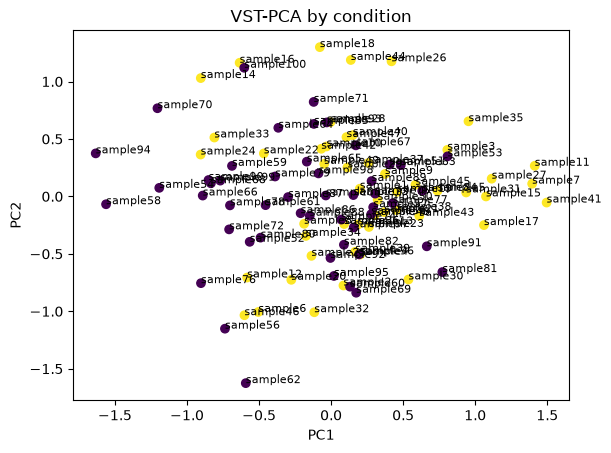

In [105]:
# Variance-stabilizing transformation (VST) is available in PyDESeq2
dds.vst()  # stores transformed values
vst = dds.layers["vst_counts"]  # samples x genes
 
# Basic PCA with scikit-learn
import numpy as np
from sklearn.decomposition import PCA
 
X = np.asarray(vst)                         # make sure it's a numeric array
pca = PCA(n_components=2).fit_transform(X)  # PCs across samples
 
# Plot, color by condition
cond = metadata["condition"].values
import matplotlib.pyplot as plt
plt.scatter(pca[:, 0], pca[:, 1], c=(cond == cond[0]))  # quick demo: two colors
for i, sid in enumerate(metadata.index):
    plt.text(pca[i, 0], pca[i, 1], sid, fontsize=8)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("VST-PCA by condition")
plt.show()

In [106]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Use the results already calculated by DeseqStats.
results_df = ds.results_df.copy()

# -------------------------
# MA plot
# -------------------------
ma_df = results_df.dropna(
    subset=["baseMean", "log2FoldChange", "padj"]
).copy()
ma_df = ma_df.loc[ma_df["baseMean"] > 0].copy()

significant = ma_df["padj"] < 0.05
increased = significant & (ma_df["log2FoldChange"] > 0)
decreased = significant & (ma_df["log2FoldChange"] < 0)

n_increased = int(increased.sum())
n_decreased = int(decreased.sum())

ma_df["status"] = "Not significant"
ma_df.loc[increased, "status"] = "Increased"
ma_df.loc[decreased, "status"] = "Decreased"

fig, ax = plt.subplots(figsize=(7.5, 5.5))

for status, color in [
    ("Not significant", "#B0B0B0"),
    ("Increased", "#D95F02"),
    ("Decreased", "#1B9E77"),
]:
    subset = ma_df.loc[ma_df["status"] == status]
    ax.scatter(
        subset["baseMean"],
        subset["log2FoldChange"],
        color=color,
        alpha=0.55 if status == "Not significant" else 0.8,
        s=12 if status == "Not significant" else 18,
        label=f"{status} (n={len(subset)})",
        rasterized=True,
    )

ax.axhline(0, color="black", linestyle="--", linewidth=0.9)
ax.set_xscale("log")
ax.set_xlabel("Mean of normalized counts (baseMean, log scale)")
ax.set_ylabel("Log2 fold change")
ax.set_title("MA plot (BH-adjusted p-value < 0.05)")
ax.legend(frameon=True, loc="best")
fig.tight_layout()
fig.savefig("ma_plot.png", dpi=300)
plt.close(fig)

# -------------------------
# VST and PCA
# -------------------------
dds.vst(use_design=False, fit_type="parametric")

vst_df = pd.DataFrame(
    dds.layers["vst_counts"],
    index=dds.obs_names,
    columns=dds.var_names,
)

if min(vst_df.shape) < 2:
    raise ValueError("PCA requires at least 2 samples and 2 genes.")

top_var_genes = vst_df.var(axis=0).nlargest(
    min(500, vst_df.shape[1])
).index

pca = PCA(n_components=2)
pca_coords = pca.fit_transform(vst_df.loc[:, top_var_genes])

metadata_df = dds.obs.loc[vst_df.index].copy()
if "condition" not in metadata_df.columns:
    raise KeyError("dds.obs must contain a 'condition' column for the PCA plot.")

size_factors = dds.obs.loc[vst_df.index, "size_factors"].to_numpy()

pca_df = pd.DataFrame(
    {
        "PC1": pca_coords[:, 0],
        "PC2": pca_coords[:, 1],
        "Condition": metadata_df["condition"].astype(str).to_numpy(),
        "SizeFactor": size_factors,
    },
    index=vst_df.index,
)

# Mean correlation of each sample with the other samples.
corr_matrix = vst_df.T.corr(method="pearson")
corr_values = corr_matrix.to_numpy(copy=True)
np.fill_diagonal(corr_values, np.nan)
corr_matrix = pd.DataFrame(corr_values, index=corr_matrix.index, columns=corr_matrix.columns)
pca_df["Mean_Sample_Corr"] = corr_matrix.mean(axis=1)

print("Sample diagnostics:")
print(pca_df.round(3))

fig, ax = plt.subplots(figsize=(7, 5.5))
colors = plt.get_cmap("tab10")

for i, (condition, subset) in enumerate(
    pca_df.groupby("Condition", sort=False)
):
    ax.scatter(
        subset["PC1"],
        subset["PC2"],
        label=condition,
        color=colors(i % 10),
        s=90,
        edgecolor="black",
    )

for sample_id, row in pca_df.iterrows():
    ax.annotate(
        str(sample_id),
        (row["PC1"], row["PC2"]),
        xytext=(4, 3),
        textcoords="offset points",
        fontsize=8,
    )

var_explained = pca.explained_variance_ratio_ * 100
ax.set_xlabel(f"PC1 ({var_explained[0]:.1f}% variance)")
ax.set_ylabel(f"PC2 ({var_explained[1]:.1f}% variance)")
ax.set_title("PCA of VST counts (top variable genes)")
ax.legend(title="Condition")
fig.tight_layout()
fig.savefig("pca_vst.png", dpi=300)
plt.close(fig)

print("Saved ma_plot.png and pca_vst.png")

Sample diagnostics:
             PC1    PC2 Condition  SizeFactor  Mean_Sample_Corr
sample1    0.199  0.067         A       1.229             0.805
sample2    0.086 -0.775         A       1.189             0.684
sample3    0.806  0.405         A       0.997             0.765
sample4    0.202 -0.506         A       1.002             0.762
sample5    0.738  0.049         A       0.835             0.818
...          ...    ...       ...         ...               ...
sample96   0.194 -0.505         B       1.269             0.759
sample97   0.157 -0.269         B       0.744             0.809
sample98  -0.088  0.200         B       0.740             0.702
sample99  -0.769  0.137         B       0.959             0.676
sample100 -0.603  1.120         B       0.636             0.600

[100 rows x 5 columns]
Saved ma_plot.png and pca_vst.png


In [107]:
# %matplotlib inline
# %config InlineBackend.figure_format = 'retina'  # crisper figures on HiDPI/Mac screens
%load_ext autoreload
%autoreload 2

import pandas as pd
import matplotlib.pyplot as plt
import gseapy as gp 

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [108]:
%pip install gseapy 

Note: you may need to restart the kernel to use updated packages.


In [109]:
import gseapy as gp

In [110]:
gp.__version__

'1.3.2'

In [112]:
# Ensembl BioMart is failing its TLS handshake in this environment.
# Query MyGene.info for the same gene-symbol, Entrez, and GO annotations.
import requests
import pandas as pd

gene_ids = ['ENSG00000125285', 'ENSG00000182968']
annotation_rows = []
for gene_id in gene_ids:
    response = requests.get(
        'https://mygene.info/v3/query',
        params={
            'q': f'ensembl.gene:{gene_id}',
            'fields': 'symbol,entrezgene,go',
            'species': 'human',
        },
        timeout=20,
    )
    response.raise_for_status()
    hits = response.json().get('hits', [])
    if not hits:
        raise LookupError(f'No human gene annotation found for {gene_id}.')

    hit = hits[0]
    go_ids = sorted(
        {
            item['id']
            for category in hit.get('go', {}).values()
            for item in category
            if 'id' in item
        }
    )
    annotation_rows.append(
        {
            'ensembl_gene_id': gene_id,
            'external_gene_name': hit.get('symbol'),
            'entrezgene_id': hit.get('entrezgene'),
            'go_id': ';'.join(go_ids),
        }
    )

results = pd.DataFrame(annotation_rows)
results.tail()

,ensembl_gene_id,external_gene_name,entrezgene_id,go_id
0,ENSG00000125285,SOX21,11166,GO:0000122;GO:0000785;GO:0000978;GO:0000981;GO...
1,ENSG00000182968,SOX1,6656,GO:0000122;GO:0000785;GO:0000978;GO:0000981;GO...


In [ ]:
# Run analyze_gse224740_propionate.py first to generate the VST and DE tables.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

tables_dir_name = Path("results") / "tables"
project_root = Path.cwd()
for candidate in (project_root, *project_root.parents):
    if (candidate / tables_dir_name / "GSE224740_3day_vst_expression.csv").is_file():
        project_root = candidate
        break
else:
    raise FileNotFoundError(
        "Run src/analyze_gse224740_propionate.py first to create the GEO VST table."
    )

tables_dir = project_root / tables_dir_name
vst_df = pd.read_csv(
    tables_dir / "GSE224740_3day_vst_expression.csv", index_col="sample"
)
de_results = pd.read_csv(
    tables_dir / "GSE224740_propionate_vs_control_deseq2.csv",
    index_col="Ensembl_ID",
)
sample_metadata = pd.read_csv(
    tables_dir / "GSE224740_3day_library_sizes.csv", index_col="sample"
)

# Select the 15 genes with the smallest BH-adjusted p-values.
ranked = de_results.dropna(subset=["padj"]).sort_values("padj")
selected_genes = [gene for gene in ranked.index if gene in vst_df.columns][:15]
if len(selected_genes) < 10:
    raise ValueError(f"Expected 10-20 genes, found only {len(selected_genes)}.")

sample_order = [
    sample
    for condition in ["Control", "Propionate"]
    for sample in sample_metadata.index[sample_metadata["condition"] == condition]
]
gene_by_sample = vst_df.loc[sample_order, selected_genes].T
row_sd = gene_by_sample.std(axis=1, ddof=0).replace(0, np.nan)
gene_z_scores = gene_by_sample.sub(gene_by_sample.mean(axis=1), axis=0).div(
    row_sd, axis=0
)
gene_z_scores.to_csv(
    tables_dir / "GSE224740_top15_vst_gene_heatmap_zscores.csv",
    index_label="Ensembl_ID",
)

figures_dir = project_root / "results" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(
    gene_z_scores.to_numpy(),
    aspect="auto",
    interpolation="nearest",
    cmap="coolwarm",
    vmin=-2,
    vmax=2,
)
ax.set_xticks(
    np.arange(len(sample_order)),
    labels=sample_order,
    rotation=45,
    ha="right",
    fontsize=8,
)
ax.set_yticks(np.arange(len(selected_genes)), labels=selected_genes)
ax.axvline(2.5, color="black", linewidth=1)
ax.set_xlabel("Samples (Control followed by Propionate)")
ax.set_ylabel("Ensembl gene ID")
ax.set_title("Top 15 differentially expressed genes: GSE224740, 3 days")
fig.colorbar(image, ax=ax, label="Gene-wise z-score of VST expression")
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.text(
    0.5,
    0.02,
    "Caption: PyDESeq2 VST values; each gene (row) is z-scored across the six samples.",
    ha="center",
    fontsize=9,
)
fig.savefig(figures_dir / "GSE224740_top15_vst_gene_heatmap.png", dpi=300)
plt.show()
plt.close(fig)
print("Selected genes (ranked by adjusted p-value):", selected_genes)